# Nudge Problem: Baselines

This notebook follows the main ideas of **Week 3** (logistic regression as a perceptron, sigmoid, cross-entropy loss) and the review session's **Vignette E** ("Read Between the Lines", answer key p21): a model on word counts throws away order.

The question every model answers: **a shopper has just left the shop without buying. Will they come back and buy within 7 days on their own?** If yes, a discount would be wasted margin.

1. Load the visits and split them by shopper into train, validation and test.
2. Turn each visit into numbers.
3. Build three baselines: **random**, the **industry rule** (discount everyone who leaves a cart), and **logistic regression on word counts**.
4. Choose cut-offs on validation, then score everything **once** on test.
5. Count the money: discount given to shoppers who would have come back anyway.

The RNN (`03_rnn`) and the Transformer (`04_transformer`) must beat these numbers on the same test shoppers.

**Owner:** TBD (Comparison role)

## 0. One-time setup
The project's `.venv` already has everything. On a new computer:

In [1]:
# %pip install -r ../requirements.txt

## 1. Import the packages
- `numpy`, `pandas`: arrays and the table of visits
- `torch`, `torch.nn`: the logistic regression model, trained with the same loop as the later models
- `sklearn.metrics`: confusion matrix and scores; `sklearn.linear_model`: only as a cross-check
- `nudge.train`, `nudge.evaluate`: our shared helpers, written like the course notebooks

In [2]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))   # repo root, so we can import nudge

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.linear_model import LogisticRegression as SklearnLogisticRegression

from nudge.contract import VOCAB
from nudge.train import SEED, set_seed, visits_to_ids, word_counts, make_loader, train_model, evaluate, predict_proba, plot_history
from nudge.evaluate import pick_cutoff, quality, money, bootstrap

set_seed(SEED)
torch.set_num_threads(4)   # keep the Mac responsive

## 2. Load the visits
One row = one visit that ended without a purchase (rules in `nudge/contract.py`, decided after the data audit):
a visit ends after 60 minutes without a click, which is when Hostinger Reach would send its email.
**Label 1** = the same shopper comes back and buys within 7 days, with no message.

The split is **by shopper** (80% / 10% / 10%): no test shopper is ever seen in training, so the test score measures how Nudge works on new people. The course splits rows at random (chapter 5 c11); we cannot, because one shopper has many visits and the model would recognise them.

In [3]:
visits = pd.read_parquet("../data/raw/visits_10pct.parquet")   # the full data (not in git); the team sample is data/sample/visits_sample.parquet
train_df = visits[visits["split"] == "train"].reset_index(drop=True)
val_df = visits[visits["split"] == "valid"].reset_index(drop=True)
test_df = visits[visits["split"] == "test"].reset_index(drop=True)

for name, df in [("train", train_df), ("validation", val_df), ("test", test_df)]:
    print(f"{name:10s} {len(df):8,} visits | {df['label'].mean():.1%} come back and buy")

train       933,419 visits | 8.7% come back and buy
validation  115,544 visits | 8.6% come back and buy
test        117,531 visits | 8.6% come back and buy


## 3. Turn visits into numbers
Each click is a **token** with an index (Week 6 s24). Index 17 is a name, not a quantity (Week 3 s21), so we never feed raw ids to logistic regression. Instead we count how often each of the 62 words appears: a **bag of words**. This throws away the order, which is exactly the weakness Vignette E points at.

In [4]:
X_ids = {name: visits_to_ids(df["tokens"]) for name, df in [("train", train_df), ("val", val_df), ("test", test_df)]}
X_counts = {name: word_counts(ids) for name, ids in X_ids.items()}
y = {"train": train_df["label"].to_numpy(), "val": val_df["label"].to_numpy(), "test": test_df["label"].to_numpy()}

example = 3
print("Words:  ", list(test_df["tokens"][example]))
print("Ids:    ", X_ids["test"][example][:8], "...")
nonzero = {VOCAB[i + 1]: int(c) for i, c in enumerate(X_counts["test"][example]) if c}
print("Counts: ", nonzero)

Words:   ['returning', 'view_expensive_start', 'view_expensive_long', 'view_expensive_quick', 'view_expensive_again_normal', 'view_expensive_quick', 'view_expensive_again_normal', 'view_expensive_again_quick', 'view_expensive_normal', 'view_expensive_again_quick', 'view_expensive_again_away', 'view_mid_long', 'view_cheap_long', 'view_cheap_normal', 'view_cheap_long', 'view_cheap_again_long', 'view_cheap_again_quick']
Ids:     [ 2 23 26 24 30 24 30 29] ...
Counts:  {'returning': 1, 'view_cheap_normal': 1, 'view_cheap_long': 2, 'view_cheap_again_quick': 1, 'view_cheap_again_long': 1, 'view_mid_long': 1, 'view_expensive_start': 1, 'view_expensive_quick': 2, 'view_expensive_normal': 1, 'view_expensive_long': 1, 'view_expensive_again_quick': 2, 'view_expensive_again_normal': 2, 'view_expensive_again_away': 1}


## 4. Baseline 1: random
A coin flip. Any model must beat this, or it has learned nothing.

In [5]:
rng = np.random.default_rng(SEED)
scores = {"Random": {"val": rng.uniform(size=len(val_df)), "test": rng.uniform(size=len(test_df))}}

## 5. Baseline 2: the industry rule
Hostinger Reach (email 1 h after the cart is left), Shopify (default 10 h, optional discount code on every recovery email) and Klaviyo (first email after 4 h) all treat every cart the same: **left a cart → discount**. None of them decides *who* gets it. As a score: 1 if the visit has a cart, else 0 (tiny random noise only breaks ties).

In [6]:
scores["Industry rule"] = {
    part: (df["cart_value"].to_numpy() > 0) + 1e-6 * rng.uniform(size=len(df))
    for part, df in [("val", val_df), ("test", test_df)]
}

## 6. Baseline 3: logistic regression (Week 3 s16–s19)
A perceptron with a sigmoid: $z = \sum_i w_i x_i + b$, $p = \sigma(z) = 1/(1+e^{-z})$, where $x_i$ is the count of word $i$.
Loss = negative log-likelihood (binary cross-entropy, Week 3 s18):
$L(w) = -\sum_i \left[y^{(i)} \log \sigma(z^{(i)}) + (1-y^{(i)}) \log(1-\sigma(z^{(i)}))\right]$.
`BCEWithLogitsLoss` computes exactly this with the sigmoid inside, which is more stable (Week 3 s19: σ is flat at the extremes).
We train it with the **same loop** as the RNN and Transformer: forward pass, loss, backward pass, Adam step.

Number of parameters: 63


/Users/kriksciunas/hostinger_presentation_project/nudge/train.py:63: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /Users/runner/work/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:214.)
  target_tensor = torch.as_tensor(targets, dtype=torch.float32)


Epoch  1/8 | train loss 0.2960 | val loss 0.2778 | val PR-AUC 0.164


Epoch  2/8 | train loss 0.2792 | val loss 0.2777 | val PR-AUC 0.164


Epoch  3/8 | train loss 0.2792 | val loss 0.2775 | val PR-AUC 0.165


Epoch  4/8 | train loss 0.2791 | val loss 0.2777 | val PR-AUC 0.165


Epoch  5/8 | train loss 0.2791 | val loss 0.2774 | val PR-AUC 0.166


Epoch  6/8 | train loss 0.2790 | val loss 0.2776 | val PR-AUC 0.163


Epoch  7/8 | train loss 0.2790 | val loss 0.2781 | val PR-AUC 0.162


Epoch  8/8 | train loss 0.2790 | val loss 0.2774 | val PR-AUC 0.165


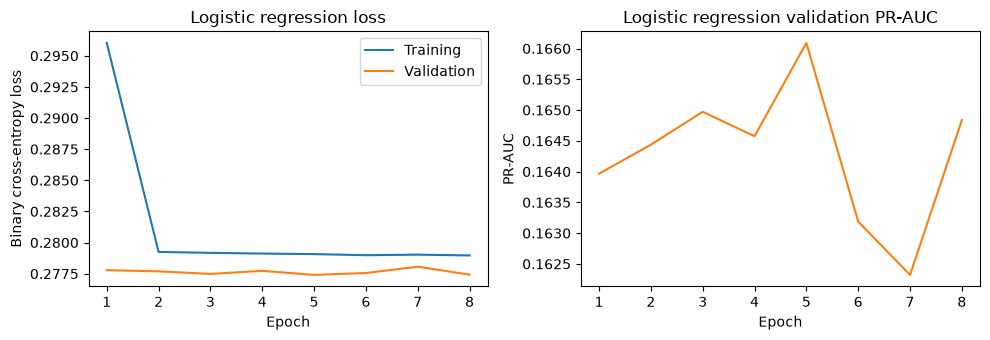

In [7]:
class LogisticRegression(nn.Module):
    """One linear layer + sigmoid: the perceptron of Week 3 s16."""
    def __init__(self, number_of_words):
        super().__init__()
        self.linear = nn.Linear(number_of_words, 1)

    def forward(self, features):
        return self.linear(features).squeeze(-1)   # one logit z per visit; sigmoid is applied in the loss

set_seed(SEED)
model = LogisticRegression(X_counts["train"].shape[1])
print("Number of parameters:", sum(p.numel() for p in model.parameters()))

train_loader = make_loader(X_counts["train"], y["train"], batch_size=1024, shuffle=True)
val_loader = make_loader(X_counts["val"], y["val"], batch_size=4096)
test_loader = make_loader(X_counts["test"], y["test"], batch_size=4096)

loss_function = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
history = train_model(model, train_loader, val_loader, loss_function, optimizer, epochs=8)
plot_history(history, "Logistic regression")

In [8]:
scores["Logistic regression"] = {"val": predict_proba(model, val_loader), "test": predict_proba(model, test_loader)}

## 7. Choose the cut-off on validation
The course predicts "yes" when $p \ge 0.5$ (Week 3 s16). Only 8.6% of visits are positive, so almost no visit reaches 0.5. We pick, **on validation only**, the cut-off with the best F1 (Week 3 s22: "keep validation and test decisions separate").

In [9]:
cutoffs = {name: pick_cutoff(y["val"], s["val"]) for name, s in scores.items()}
for name, cut in cutoffs.items():
    print(f"{name:20s} cut-off {cut:.3f}")

Random               cut-off 0.502
Industry rule        cut-off 0.000
Logistic regression  cut-off 0.112


## 8. Test once
**Precision** = of the shoppers we flag, the share who really come back. **Recall** = of the shoppers who come back, the share we flag. **F1** = their balance. **AUC** = the chance a random come-back shopper gets a higher score than a random non-buyer (0.5 = coin flip). **PR-AUC** focuses on the rare positives (random = 0.086). These are not defined in the slides; see `docs/course-map.md` section 4.
The range in brackets: we resample test **shoppers** 200 times; if two models' ranges do not overlap, the difference is not luck.

In [10]:
rows, ranges = [], {}
for name, s in scores.items():
    q = quality(y["test"], s["test"], cutoffs[name])
    frame = test_df.assign(_score=s["test"])
    ranges[name] = bootstrap(frame, lambda d, c=cutoffs[name]: {k: quality(d["label"].to_numpy(), d["_score"].to_numpy(), c)[k] for k in ("auc", "pr_auc", "f1")}, n=200, seed=SEED)
    one_click = frame["n_clicks"] == 1
    q_one = quality(frame.loc[one_click, "label"].to_numpy(), frame.loc[one_click, "_score"].to_numpy(), cutoffs[name])
    rows.append({"model": name, **{k: q[k] for k in ("auc", "pr_auc", "precision", "recall", "f1")}, "auc_one_click": q_one["auc"]})
quality_table = pd.DataFrame(rows).set_index("model")
for name in quality_table.index:
    for k in ("auc", "pr_auc", "f1"):
        lo, hi = ranges[name][k]
        quality_table.loc[name, f"{k}_95%"] = f"{lo:.3f}–{hi:.3f}"
quality_table.round(3)

,auc,pr_auc,precision,recall,f1,auc_one_click,auc_95%,pr_auc_95%,f1_95%
model,,,,,,,,,
Random,0.498,0.085,0.086,0.496,0.146,0.498,0.492–0.504,0.082–0.089,0.140–0.152
Industry rule,0.556,0.122,0.208,0.184,0.195,0.500,0.549–0.562,0.116–0.128,0.186–0.205
Logistic regression,0.676,0.157,0.161,0.370,0.224,0.657,0.670–0.682,0.148–0.165,0.215–0.233


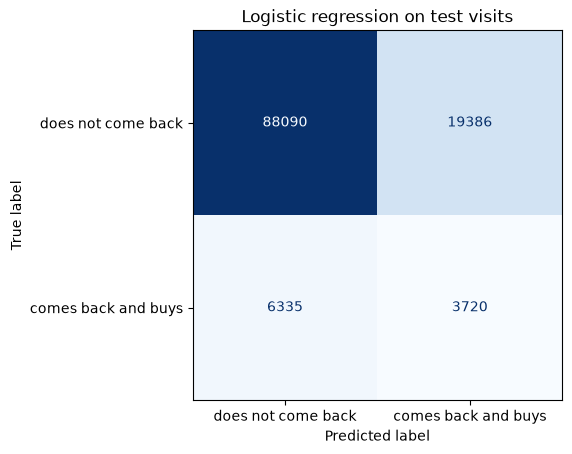

In [11]:
ConfusionMatrixDisplay.from_predictions(y["test"], scores["Logistic regression"]["test"] >= cutoffs["Logistic regression"],
                                        display_labels=["does not come back", "comes back and buys"], cmap="Blues", colorbar=False)
plt.title("Logistic regression on test visits")
plt.show()

## 9. Money: who gets the 10% discount?
Only **cart abandoners**, the people today's flows discount. A model gives the discount only to the cart abandoners it thinks will **not** come back on their own. To compare fairly with random, both send the same share of discounts (80%, 60%, 40%). Every policy: at most one discount per shopper per 7 days.
- **€ wasted** = 10% of what a shopper actually bought, for shoppers who got the discount and came back anyway.
- **Left without a nudge** = cart abandoners we skipped who did not come back. Whether a discount would have brought them back is unknown: only an A/B test can say.

In [12]:
cart_val = val_df["cart_value"].to_numpy() > 0
lr_val_cart = scores["Logistic regression"]["val"][cart_val]
frame = test_df.assign(_p=scores["Logistic regression"]["test"], _r=np.random.default_rng(SEED + 1).uniform(size=len(test_df)))

money_rows = []
for keep in (1.0, 0.8, 0.6, 0.4):
    cut = np.quantile(lr_val_cart, keep) if keep < 1 else np.inf
    policies = {"Logistic regression": lambda d, c=cut: d["_p"].to_numpy() < c,
                "Random": lambda d, k=keep: d["_r"].to_numpy() < k}
    for name, policy in policies.items():
        if keep == 1.0 and name == "Random":
            continue
        label = "Industry rule (everyone)" if keep == 1.0 else name
        m = money(frame, policy(frame))
        ci = bootstrap(frame, lambda d, f=policy: money(d, f(d)), n=200, seed=SEED)
        money_rows.append({"policy": label, "share": f"{keep:.0%}", "discounts": m["discounts_sent"],
                           "€ wasted": round(m["wasted_eur"]), "€ wasted 95%": f"{ci['wasted_eur'][0]:,.0f}–{ci['wasted_eur'][1]:,.0f}",
                           "spared, came back": m["spared_discount_came_back"], "left without a nudge": m["left_without_nudge"]})
money_table = pd.DataFrame(money_rows)
money_table

,policy,share,discounts,€ wasted,€ wasted 95%,"spared, came back",left without a nudge
0,Industry rule (everyone),100%,6622,50327,"44,510–56,529",651,1568
1,Logistic regression,80%,5742,40298,"35,384–45,417",865,2234
2,Random,80%,5505,42737,"37,431–48,432",834,2502
3,Logistic regression,60%,4619,30202,"26,380–34,426",1084,3138
4,Random,60%,4326,35745,"30,970–40,977",1017,3498
5,Logistic regression,40%,3369,19756,"17,239–22,835",1335,4137
6,Random,40%,3047,26242,"21,839–30,908",1250,4544


## 10. What logistic regression learned
Each word has one weight $w_i$. A positive weight raises the chance of coming back, a negative one lowers it (Week 3 s16: $z = \sum w_i x_i + b$).

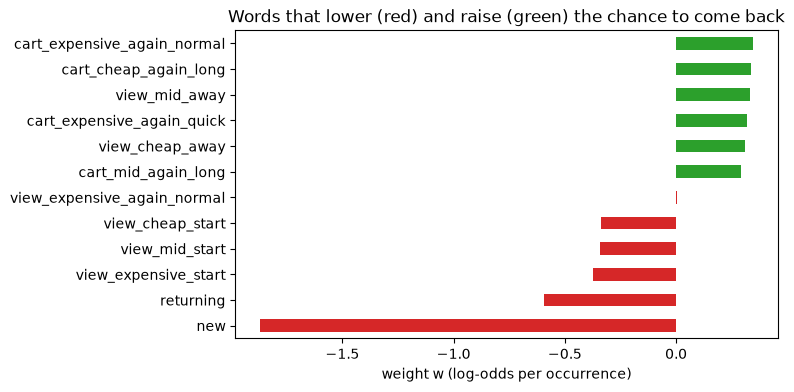

In [13]:
weights = pd.Series(model.linear.weight.detach().cpu().numpy().ravel(), index=VOCAB[1:])
used = pd.Series(X_counts["train"].sum(axis=0), index=VOCAB[1:])
weights = weights[used >= 200].sort_values()
pd.concat([weights.head(6), weights.tail(6)]).plot.barh(figsize=(7, 4), color=["tab:red"] * 6 + ["tab:green"] * 6)
plt.xlabel("weight w (log-odds per occurrence)")
plt.title("Words that lower (red) and raise (green) the chance to come back")
plt.show()

## 11. Cross-check with scikit-learn
The course does not use scikit-learn models, but if our PyTorch logistic regression is right, scikit-learn's should score almost the same.

In [14]:
sk = SklearnLogisticRegression(max_iter=2000).fit(X_counts["train"], y["train"])
sk_auc = quality(y["test"], sk.predict_proba(X_counts["test"])[:, 1], 0.5)["auc"]
print(f"PyTorch AUC {quality_table.loc['Logistic regression', 'auc']:.3f} | scikit-learn AUC {sk_auc:.3f}")

PyTorch AUC 0.676 | scikit-learn AUC 0.675


## 12. Save the results for the report

In [15]:
pathlib.Path("../results").mkdir(exist_ok=True)
quality_table.round(3).to_csv("../results/baselines_quality.csv")
money_table.to_csv("../results/baselines_money.csv", index=False)
torch.save({"config": {"number_of_words": X_counts["train"].shape[1]}, "state_dict": model.state_dict(),
            "cutoff": cutoffs["Logistic regression"], "seed": SEED}, "../results/logistic_regression.pt")
print("saved")

saved


## 13. Connect the code to the course
| Idea | Where it appears here | Course |
|---|---|---|
| Tokens and vocabulary | section 3, `visits_to_ids` | Week 6 s24 |
| An index is a name, not a quantity | section 3, counts instead of ids | Week 3 s21 |
| Counts throw away order | section 3 and 6 | Review session, Vignette E (AK p21) |
| Perceptron with sigmoid | section 6, `LogisticRegression` | Week 3 s16–s17 |
| Cross-entropy / negative log-likelihood | section 6, `BCEWithLogitsLoss` | Week 3 s18 |
| Forward, loss, backward, step | `train_model` | Week 3 s26–s29, chapter 5 c21 |
| Train / validation / test, keep the best epoch | sections 2, 6 and 8 | chapter 5 c10, c22 |
| Report class-specific errors and costs | sections 8 and 9 | Week 3 s22 |

## Reflection questions
1. Why is the cut-off chosen on validation and not on test?
2. Logistic regression sends fewer discounts than the industry rule. Why is "€ wasted" alone not enough to call it better? What does the "left without a nudge" column add?
3. Which word has the most negative weight, and why does that make sense for a shop?
4. Two visits contain the same words in a different order. What does logistic regression predict for them, and why is that the reason for building an RNN next?